# 02 · Preprocesamiento y extracción de features (3 clases: Normal / Aggression / Theft)

Documenta el pipeline de datos **solo para las clases que estudia la tesis** (mapeo leído de `configs/hr320_v2.yaml`):

| Clase | Categorías UCF-Crime |
|---|---|
| **Normal** | NormalVideos |
| **Aggression** | Assault, Abuse, Fighting |
| **Theft** | Robbery, Burglary, Stealing, Shoplifting |

| Paso | Artefacto |
|---|---|
| Versionado del dataset | `data/manifests_320/*.json`, `metadata.json` |
| Splits train/val/test e integridad | `data/processed/ucf_crime_3class_320_v2/splits/*.jsonl` |
| Filtro de calidad (brillo) | `excluded_videos.csv` |
| Frames 320×240 | `data/raw/ucf_crime_320/{Train,Test}/<categoría>/<video>_<idx>.jpg` |
| Muestreo temporal (L=16) y movimiento | se recalcula aquí sobre ejemplos |
| Features pre-extraídas | `data/processed/features/<variante>/*.npz` (solo se usan los videos de las 3 clases) |

> La lógica oficial vive en `src/vad/`; este notebook la **ejecuta y muestra**.

## 0. Configuración

In [1]:
import os, re, json, random
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
random.seed(SEED); np.random.seed(SEED)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# ── Mapeo de clases: se lee del MISMO yaml que usó `vad preprocess` ──────────
CONFIG = ROOT / "configs" / "hr320_v2.yaml"

DEFAULT_MAPPING = {                       # respaldo si no se puede leer el yaml
    "Normal":     ["NormalVideos"],
    "Aggression": ["Assault", "Abuse", "Fighting"],
    "Theft":      ["Robbery", "Burglary", "Stealing", "Shoplifting"],
}
PROC_DIR = ROOT / "data" / "processed" / "ucf_crime_3class_320_v2"
RAW_DIR = ROOT / "data" / "raw" / "ucf_crime_320"          # frames 320×240
VIDEOS_DIR = ROOT / "data" / "raw" / "ucf_crime_videos"    # mp4 originales
MIN_BRIGHTNESS = 30
CLASS_MAPPING, CLASS_TO_IDX = DEFAULT_MAPPING, None
try:
    import yaml
    _cfg = yaml.safe_load(CONFIG.read_text(encoding="utf-8"))
    CLASS_MAPPING = _cfg["preprocess"]["class_mapping"]
    CLASS_TO_IDX = _cfg["preprocess"].get("class_to_idx")
    MIN_BRIGHTNESS = _cfg["preprocess"].get("min_brightness", MIN_BRIGHTNESS)
    PROC_DIR = ROOT / _cfg["paths"]["processed_dir"]
    RAW_DIR = ROOT / _cfg["paths"]["raw_dir"]
    VIDEOS_DIR = ROOT / _cfg.get("videos", {}).get("dir", "data/raw/ucf_crime_videos")
    print("Config:", CONFIG.relative_to(ROOT))
except Exception as e:
    print(f"[AVISO] No se pudo leer {CONFIG} ({e}) → uso el mapeo por defecto")

CLASSES = sorted(CLASS_MAPPING, key=lambda c: CLASS_TO_IDX[c]) if CLASS_TO_IDX else list(CLASS_MAPPING)
CAT_TO_CLASS = {cat: cls for cls, cats in CLASS_MAPPING.items() for cat in cats}
COLORS = dict(zip(CLASSES, ["#4C72B0", "#C44E52", "#DD8452", "#55A868", "#8172B2"]))

print("Clases estudiadas:", CLASSES)
for c in CLASSES:
    print(f"  {c:<11} ← {', '.join(CLASS_MAPPING[c])}")
print("Todo lo demás (Arson, Explosion, Vandalism, RoadAccidents, Arrest, Shooting) queda FUERA del análisis.")

FEAT_DIR     = ROOT / "data/processed/features"
MANIFEST_DIR = ROOT / "data/manifests_320"
L_SEGMENTS = 16
IMG_SIZE = 224

for p in [RAW_DIR, PROC_DIR, FEAT_DIR, MANIFEST_DIR]:
    print("OK " if p.exists() else "NO ", p.relative_to(ROOT))


Config: configs\hr320_v2.yaml
Clases estudiadas: ['Normal', 'Aggression', 'Theft']
  Normal      ← NormalVideos
  Aggression  ← Assault, Abuse, Fighting
  Theft       ← Robbery, Burglary, Stealing, Shoplifting
Todo lo demás (Arson, Explosion, Vandalism, RoadAccidents, Arrest, Shooting) queda FUERA del análisis.
OK  data\raw\ucf_crime_320
OK  data\processed\ucf_crime_3class_320_v2
OK  data\processed\features
OK  data\manifests_320


## 1. Versionado del dataset

In [2]:
def show_json(p, n=1200):
    if not p.exists():
        print("No existe:", p.relative_to(ROOT)); return
    txt = json.dumps(json.load(open(p, encoding="utf-8")), indent=2, ensure_ascii=False)
    print(f"--- {p.relative_to(ROOT)} ---")
    print(txt[:n] + ("\n..." if len(txt) > n else ""))

for p in [MANIFEST_DIR / "raw_dataset_version.json",
          MANIFEST_DIR / "processed_dataset_version.json",
          PROC_DIR / "metadata.json"]:
    show_json(p)

--- data\manifests_320\raw_dataset_version.json ---
{
  "dataset": "UCF-Crime (videos originales → frames 320×240)",
  "source_url": "https://www.crcv.ucf.edu/projects/real-world/",
  "download_date": "2026-10-01",
  "ingested_at": "2026-10-01T20:32:32+00:00",
  "raw_dir": "data/raw/ucf_crime_320",
  "hash_mode": "sha256 por archivo",
  "dataset_sha256": "b5624813ff432dbb39fb6c7050aab133e07f564af938239a1d44a39c1a4e7b0d",
  "totals": {
    "videos": 1650,
    "frames": 1306972,
    "bytes": 42938383931,
    "bytes_human": "40.0 GB"
  },
  "per_split": {
    "Test": {
      "videos": 239,
      "frames": 97650,
      "bytes": 3124799692
    },
    "Train": {
      "videos": 1411,
      "frames": 1209322,
      "bytes": 39813584239
    }
  },
  "per_category": {
    "Test/Abuse": {
      "videos": 2,
      "frames": 297,
      "bytes": 9388121,
      "sha256": "1edc01badf40b0da42edc51390153079c9978d0701aac7e019c75d97ef73f399"
    },
    "Test/Arson": {
      "videos": 9,
      "frames": 2

## 2. Splits train / val / test

In [3]:
dfs = []
for f in sorted((PROC_DIR / "splits").glob("*.jsonl")):
    d = pd.read_json(f, lines=True)
    d["split"] = f.stem
    dfs.append(d)
splits = pd.concat(dfs, ignore_index=True)
splits = splits[splits["class_name"].isin(CLASSES)].reset_index(drop=True)   # solo las 3 clases
print("Columnas:", splits.columns.tolist())
splits.head()


Columnas: ['video_id', 'ucf_category', 'class_name', 'source_split', 'label', 'n_frames', 'brightness', 'frame_indices', 'frames', 'split']


,video_id,ucf_category,class_name,source_split,label,n_frames,brightness,frame_indices,frames,split
0,Normal_Videos_003_x264,NormalVideos,Normal,Test,0,283,68.6,"[0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 1...",[Test/NormalVideos/Normal_Videos_003_x264_0.jp...,test
1,Normal_Videos_006_x264,NormalVideos,Normal,Test,0,45,100.5,"[0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 1...",[Test/NormalVideos/Normal_Videos_006_x264_0.jp...,test
2,Normal_Videos_010_x264,NormalVideos,Normal,Test,0,106,52.2,"[0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 1...",[Test/NormalVideos/Normal_Videos_010_x264_0.jp...,test
3,Normal_Videos_014_x264,NormalVideos,Normal,Test,0,150,92.5,"[0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 1...",[Test/NormalVideos/Normal_Videos_014_x264_0.jp...,test
4,Normal_Videos_015_x264,NormalVideos,Normal,Test,0,48,87.6,"[0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 1...",[Test/NormalVideos/Normal_Videos_015_x264_0.jp...,test


split,train,val,test,All
class_name,,,,
Normal,160,40,150,350
Aggression,110,28,10,148
Theft,120,30,43,193
All,390,98,203,691


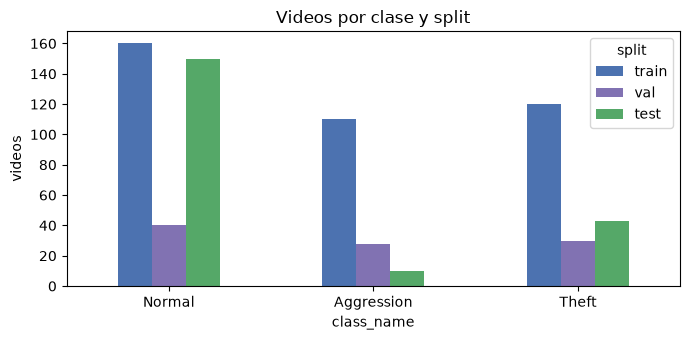

Categorías UCF dentro de cada clase:


class_name,Normal,Aggression,Theft
ucf_category,,,
Abuse,0,49,0
Assault,0,49,0
Burglary,0,0,39
Fighting,0,50,0
NormalVideos,350,0,0
Robbery,0,0,71
Shoplifting,0,0,32
Stealing,0,0,51


In [4]:
LABEL_COL, VIDEO_COL = "class_name", "video_id"
splits[LABEL_COL] = pd.Categorical(splits[LABEL_COL], categories=CLASSES, ordered=True)
splits["video_id"] = splits[VIDEO_COL].astype(str).map(lambda s: Path(s.replace("\\", "/")).stem)

ct = pd.crosstab(splits[LABEL_COL], splits["split"], margins=True)
ct = ct[[c for c in ["train", "val", "test", "All"] if c in ct.columns]]
display(ct)
ct.drop(index="All").drop(columns="All").plot.bar(figsize=(7, 3.5), title="Videos por clase y split",
                                                    color=["#4C72B0", "#8172B2", "#55A868"])
plt.ylabel("videos"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

print("Categorías UCF dentro de cada clase:")
display(pd.crosstab(splits["ucf_category"], splits[LABEL_COL]))


**Integridad del test set:** ningún video debe aparecer en más de un split.

In [5]:
sets = {s: set(g.video_id) for s, g in splits.groupby("split")}
names = sorted(sets)
for i, a in enumerate(names):
    for b in names[i + 1:]:
        print(f"{a:>6} ∩ {b:<6}: {len(sets[a] & sets[b])} videos en común")
print("Duplicados dentro de un mismo split:", splits.duplicated(["split", "video_id"]).sum())

  test ∩ train : 0 videos en común
  test ∩ val   : 0 videos en común
 train ∩ val   : 0 videos en común
Duplicados dentro de un mismo split: 0


## 3. Filtro de calidad: videos excluidos

In [6]:
exc = pd.read_csv(PROC_DIR / "excluded_videos.csv")
exc = exc[exc["ucf_category"].isin(CAT_TO_CLASS)].copy()        # solo categorías de las 3 clases
exc["class_name"] = exc["ucf_category"].map(CAT_TO_CLASS)
print("Videos excluidos (3 clases):", len(exc))
display(exc.sort_values("brightness"))
display(pd.crosstab([exc["source_split"], exc["class_name"]], exc["reason"]))


Videos excluidos (3 clases): 11


,video_id,ucf_category,class_name,source_split,reason,n_frames,brightness
9,Stealing021_x264,Stealing,Theft,Train,oscuro,413,14.6
4,Normal_Videos705_x264,NormalVideos,Normal,Train,oscuro,29,17.8
6,Normal_Videos950_x264,NormalVideos,Normal,Train,oscuro,242,22.6
5,Normal_Videos806_x264,NormalVideos,Normal,Train,oscuro,272,23.3
7,Robbery055_x264,Robbery,Theft,Train,oscuro,956,25.0
3,Burglary090_x264,Burglary,Theft,Train,oscuro,277,26.1
10,Stealing111_x264,Stealing,Theft,Train,oscuro,472,26.4
1,Abuse032_x264,Abuse,Aggression,Train,oscuro,475,28.5
8,Robbery084_x264,Robbery,Theft,Train,oscuro,322,29.2
2,Assault052_x264,Assault,Aggression,Train,oscuro,79,29.2


reason                   oscuro
source_split class_name        
Test         Theft            1
Train        Aggression       2
             Normal           3
             Theft            5

## 4. Índice de frames 320×240

In [7]:
FRAME_RE = re.compile(r"^(.*)_(\d+)\.(jpg|jpeg|png)$", re.I)
frame_index = defaultdict(list)
video_meta = {}

for split_dir in RAW_DIR.iterdir():
    if not split_dir.is_dir():
        continue
    for cls_dir in split_dir.iterdir():
        if not cls_dir.is_dir() or cls_dir.name not in CAT_TO_CLASS:   # ignora Arson, Explosion, Vandalism…
            continue
        with os.scandir(cls_dir) as it:
            for e in it:
                m = FRAME_RE.match(e.name)
                if m:
                    frame_index[m.group(1)].append((int(m.group(2)), e.path))
                    video_meta.setdefault(m.group(1), (split_dir.name, cls_dir.name))
for v in frame_index:
    frame_index[v].sort()

raw = pd.DataFrame([{"video_id": v, "raw_split": s, "clase_original": c, "clase": CAT_TO_CLASS[c],
                     "n_frames": len(frame_index[v])} for v, (s, c) in video_meta.items()])
print(f"Videos de las 3 clases con frames: {len(raw)} | frames totales: {raw.n_frames.sum():,}")
raw.groupby(["clase", "clase_original"]).n_frames.describe().round(1)


Videos de las 3 clases con frames: 1500 | frames totales: 1,239,758


count    mean     std   min    25%    50%    75%  \
clase      clase_original                                                     
Aggression Abuse            50.0   387.5   468.2  30.0  145.2  269.5  438.0   
           Assault          50.0   260.3   289.2  14.0   80.5  179.0  306.8   
           Fighting         50.0   518.3   585.2  81.0  215.8  354.0  618.2   
Normal     NormalVideos    950.0  1066.0  4561.0  21.0  110.2  215.5  486.0   
Theft      Burglary        100.0   471.6   678.1  30.0  131.0  277.0  558.2   
           Robbery         150.0   282.2   251.5  28.0  121.5  197.0  349.0   
           Shoplifting      50.0   649.2  1058.1  45.0  184.2  277.5  674.8   
           Stealing        100.0   467.9   443.2  41.0  167.2  318.5  542.2   

                               max  
clase      clase_original           
Aggression Abuse            2848.0  
           Assault          1618.0  
           Fighting         3165.0  
Normal     NormalVideos    97651.0  
Theft      Burglary         4863.0  
           Robbery          1528.0  
           Shoplifting      6670.0  
           Stealing         2182.0

In [8]:
df = splits.merge(raw.drop(columns="clase"), on="video_id", how="left", suffixes=("_split", ""))
print("Columnas tras el merge:", df.columns.tolist())

faltan = df.n_frames.isna().sum()
print("Videos del split sin frames encontrados:", faltan)
if faltan:
    display(df[df.n_frames.isna()].head())

if "n_frames_split" in df.columns:
    dif = (df.n_frames_split - df.n_frames).abs()
    print("Videos con distinto n° de frames (split vs disco):", (dif > 0).sum())

print("Remapeo categoría original -> clase:")
display(pd.crosstab(df.clase_original, df[LABEL_COL]))
df.groupby(LABEL_COL, observed=True).n_frames.describe().round(1)


Columnas tras el merge: ['video_id', 'ucf_category', 'class_name', 'source_split', 'label', 'n_frames_split', 'brightness', 'frame_indices', 'frames', 'split', 'raw_split', 'clase_original', 'n_frames']
Videos del split sin frames encontrados: 0
Videos con distinto n° de frames (split vs disco): 0
Remapeo categoría original -> clase:


class_name,Normal,Aggression,Theft
clase_original,,,
Abuse,0,49,0
Assault,0,49,0
Burglary,0,0,39
Fighting,0,50,0
NormalVideos,350,0,0
Robbery,0,0,71
Shoplifting,0,0,32
Stealing,0,0,51


,count,mean,std,min,25%,50%,75%,max
class_name,,,,,,,,
Normal,350.0,1012.3,4441.8,21.0,108.2,203.5,460.0,62802.0
Aggression,148.0,390.2,475.1,14.0,131.8,252.5,439.8,3165.0
Theft,193.0,428.9,477.5,41.0,161.0,274.0,513.0,4066.0


## 5. Brillo medio: excluidos vs. aceptados
Se usa el **brillo que calculó `vad preprocess`** (columna `brightness` de `splits/*.jsonl` y `excluded_videos.csv`: luma en escala de grises, media de 5 frames).
La versión anterior de este notebook recalculaba el brillo con el canal V de HSV (= máx(R,G,B), siempre ≥ luma) sobre 10 frames. Por eso aparecían excluidos por encima de 30: era otra métrica, no un error del filtro.

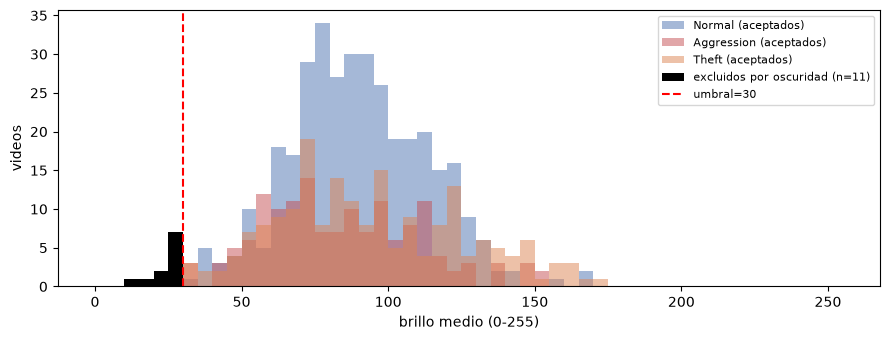

Excluidos con brillo ≥ umbral: 0 (debe ser 0)
Aceptados con brillo < umbral: 0 (debe ser 0)


,count,mean,std,min,25%,50%,75%,max
class_name,,,,,,,,
Normal,350.0,89.8,23.1,33.1,74.0,87.9,106.3,166.8
Aggression,148.0,84.8,26.7,34.1,63.7,82.4,104.6,151.3
Theft,193.0,94.1,31.7,30.2,70.8,89.0,118.4,171.9


In [9]:
def read_rgb(path, size=None):
    img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    return cv2.resize(img, (size, size)) if size else img

ok = df.dropna(subset=["n_frames"])
def sample_per_class(d, n):
    return d.sample(frac=1, random_state=SEED).groupby(LABEL_COL, observed=True).head(n)

exc_osc = exc[exc["reason"] == "oscuro"]
fig, ax = plt.subplots(figsize=(9, 3.5))
bins = np.arange(0, 256, 5)
for c in CLASSES:
    ax.hist(df.loc[df[LABEL_COL] == c, "brightness"], bins=bins, alpha=.5, label=f"{c} (aceptados)", color=COLORS[c])
ax.hist(exc_osc["brightness"], bins=bins, color="black", label=f"excluidos por oscuridad (n={len(exc_osc)})")
ax.axvline(MIN_BRIGHTNESS, color="red", ls="--", label=f"umbral={MIN_BRIGHTNESS}")
ax.set_xlabel("brillo medio (0-255)"); ax.set_ylabel("videos"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print("Excluidos con brillo ≥ umbral:", int((exc_osc["brightness"] >= MIN_BRIGHTNESS).sum()), "(debe ser 0)")
print("Aceptados con brillo < umbral:", int((df["brightness"] < MIN_BRIGHTNESS).sum()), "(debe ser 0)")
df.groupby(LABEL_COL, observed=True)["brightness"].describe().round(1)


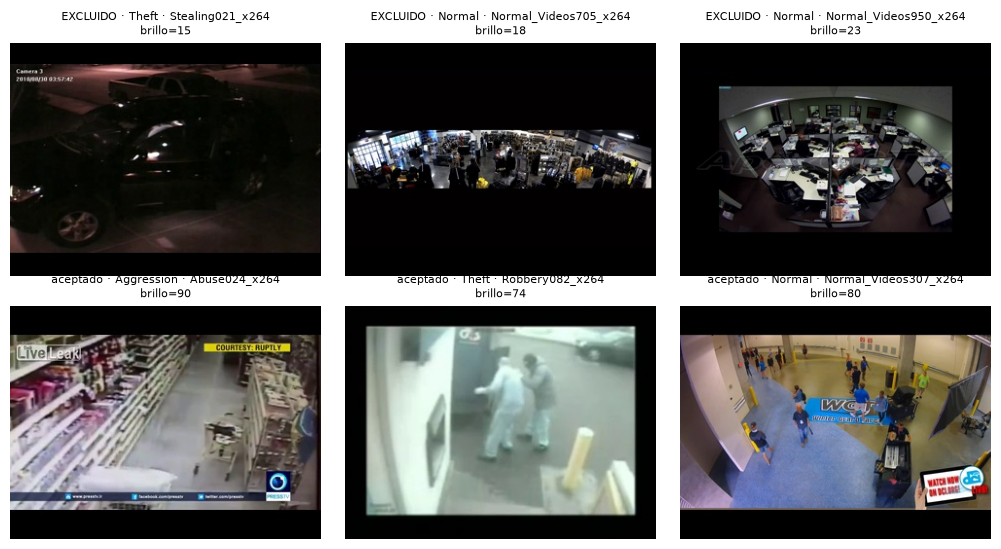

In [10]:
def mid_frame(vid, size=None):
    fr = frame_index[vid]
    return read_rgb(fr[len(fr) // 2][1], size)

ej_exc = [v for v in exc_osc.sort_values("brightness").video_id if v in frame_index][:3]
ej_acep = sample_per_class(ok, 1).video_id.tolist()
b_of = {**dict(zip(df.video_id, df.brightness)), **dict(zip(exc.video_id, exc.brightness))}
cls_of = {**dict(zip(df.video_id, df[LABEL_COL].astype(str))), **dict(zip(exc.video_id, exc.class_name))}

n = max(len(ej_exc), len(ej_acep), 1)
fig, axes = plt.subplots(2, n, figsize=(3.4 * n, 5.5), squeeze=False)
for ax in axes.flat:
    ax.axis("off")
for ax, v in zip(axes[0], ej_exc):
    ax.imshow(mid_frame(v)); ax.set_title(f"EXCLUIDO · {cls_of[v]} · {v}\nbrillo={b_of[v]:.0f}", fontsize=8)
for ax, v in zip(axes[1], ej_acep):
    ax.imshow(mid_frame(v)); ax.set_title(f"aceptado · {cls_of[v]} · {v}\nbrillo={b_of[v]:.0f}", fontsize=8)
plt.tight_layout(); plt.show()


## 6. Muestreo temporal: L = 16 segmentos
El video se divide en 16 segmentos iguales y se toma 1 frame por segmento (centro en evaluación, aleatorio dentro del segmento en entrenamiento).

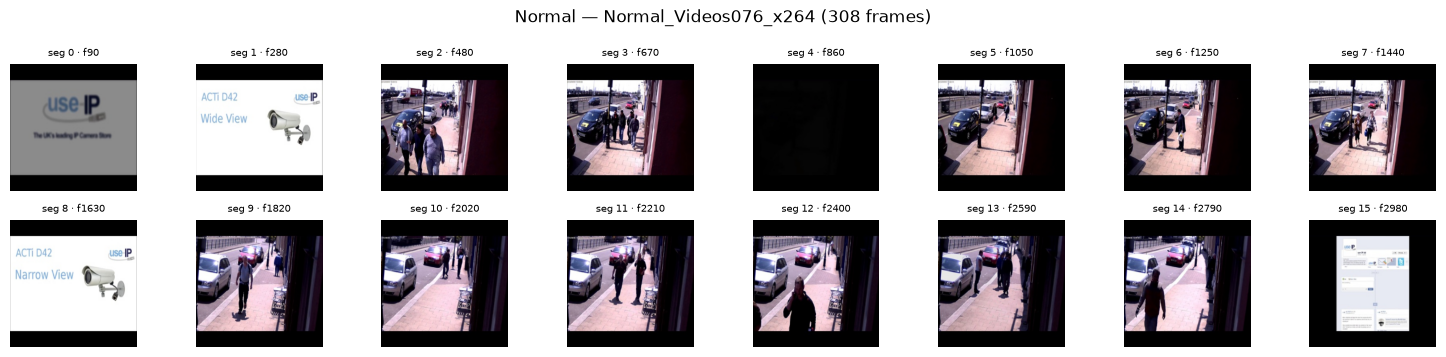

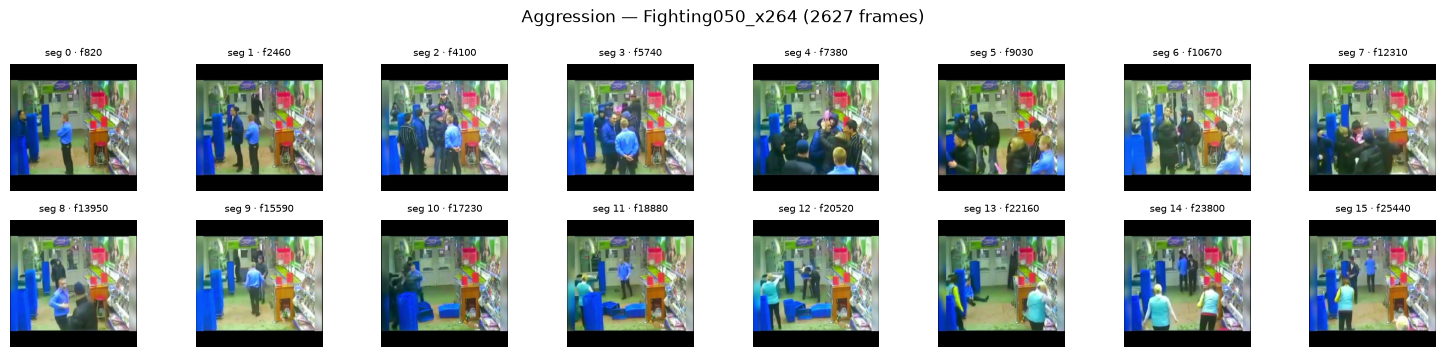

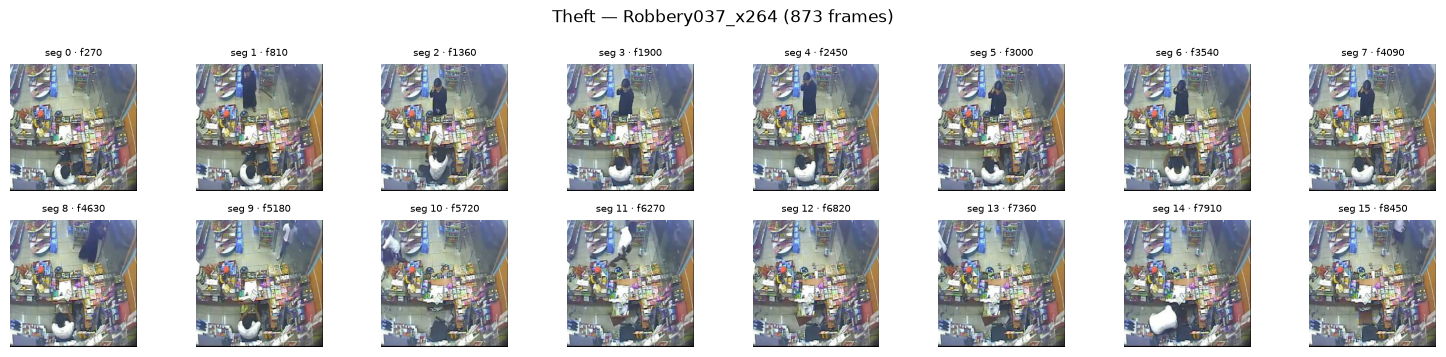

In [11]:
def sample_segments(n_frames, L=L_SEGMENTS, train=False):
    edges = np.linspace(0, n_frames, L + 1)
    if train:
        return np.array([np.random.randint(int(a), max(int(a) + 1, int(b))) for a, b in zip(edges[:-1], edges[1:])])
    return ((edges[:-1] + edges[1:]) / 2).astype(int).clip(0, n_frames - 1)

train_df = ok[ok.split.str.lower() == "train"]
demo = sample_per_class(train_df, 1).sort_values(LABEL_COL)

for _, r in demo.iterrows():
    fr = frame_index[r.video_id]
    idx = sample_segments(len(fr))
    fig, axes = plt.subplots(2, 8, figsize=(15, 3.6))
    for k, ax in enumerate(axes.flat):
        ax.imshow(read_rgb(fr[idx[k]][1], IMG_SIZE)); ax.set_title(f"seg {k} · f{fr[idx[k]][0]}", fontsize=7); ax.axis("off")
    fig.suptitle(f"{r[LABEL_COL]} — {r.video_id} ({len(fr)} frames)")
    plt.tight_layout(); plt.show()

## 7. Representaciones de movimiento: diferencia de frames vs. Farneback
Son las dos variantes de las features pre-extraídas (`*_diff_*` y `*_farneback_*`). Se calculan entre el frame muestreado y el siguiente.

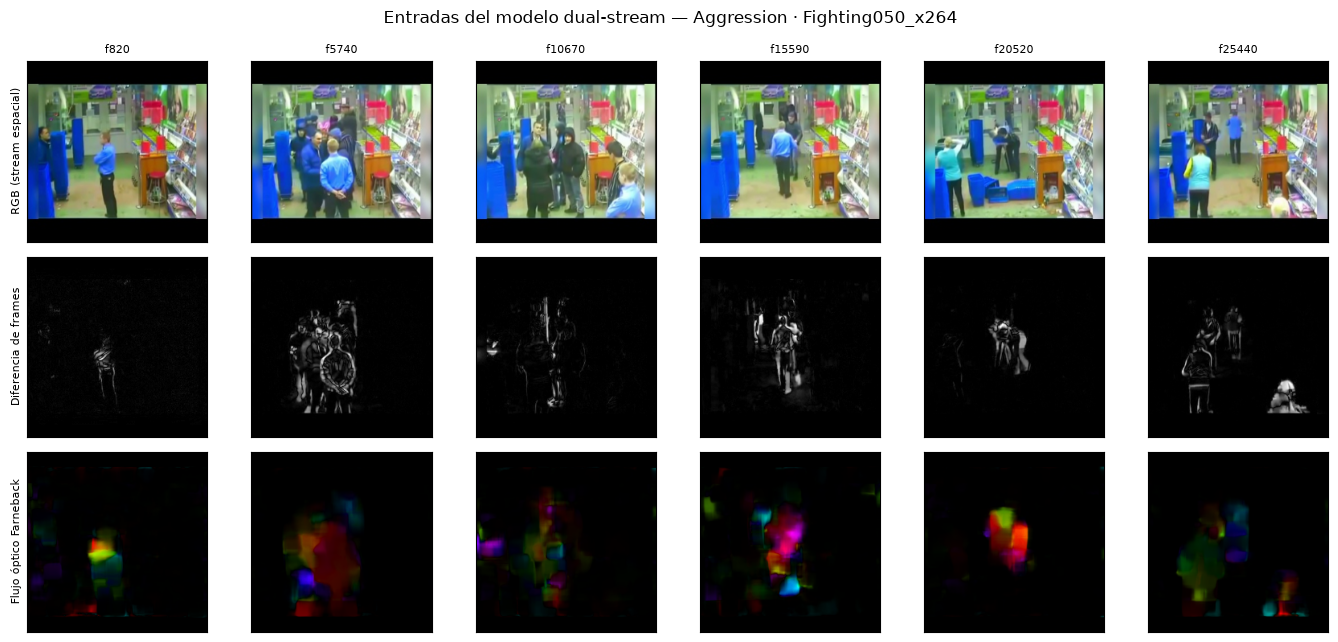

In [12]:
def motion_pair(a_rgb, b_rgb):
    a = cv2.cvtColor(a_rgb, cv2.COLOR_RGB2GRAY); b = cv2.cvtColor(b_rgb, cv2.COLOR_RGB2GRAY)
    diff = cv2.absdiff(b, a)
    flow = cv2.calcOpticalFlowFarneback(a, b, None, 0.5, 3, 15, 3, 5, 1.2, 0)
    mag, ang = cv2.cartToPolar(flow[..., 0], flow[..., 1])
    hsv = np.zeros((*a.shape, 3), np.uint8)
    hsv[..., 0] = ang * 180 / np.pi / 2; hsv[..., 1] = 255
    hsv[..., 2] = cv2.normalize(mag, None, 0, 255, cv2.NORM_MINMAX)
    return diff, cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)

anom = demo[~demo[LABEL_COL].astype(str).str.lower().str.startswith("normal")]
r = (anom if len(anom) else demo).iloc[0]
fr = frame_index[r.video_id]
idx = sample_segments(len(fr))[::3][:6]

fig, axes = plt.subplots(3, len(idx), figsize=(2.3 * len(idx), 6.5))
for k, i in enumerate(idx):
    a = read_rgb(fr[i][1], IMG_SIZE); b = read_rgb(fr[min(i + 1, len(fr) - 1)][1], IMG_SIZE)
    d, f = motion_pair(a, b)
    axes[0, k].imshow(a); axes[1, k].imshow(d, cmap="gray"); axes[2, k].imshow(f)
    axes[0, k].set_title(f"f{fr[i][0]}", fontsize=8)
for row, name in enumerate(["RGB (stream espacial)", "Diferencia de frames", "Flujo óptico Farneback"]):
    axes[row, 0].set_ylabel(name, fontsize=8)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f"Entradas del modelo dual-stream — {r[LABEL_COL]} · {r.video_id}")
plt.tight_layout(); plt.show()

## 8. Features pre-extraídas (una fila por frame extraído ≈ 0.33 s, no por segmento)
Cada variante combina un backbone (CLIP ViT-B/16 o ConvNeXt-S/T) con una representación de movimiento (diff o Farneback). Un `.npz` por video.
Las carpetas contienen todos los videos extraídos; aquí solo se usan los de las 3 clases.

In [13]:
label_of = dict(zip(df.video_id, df[LABEL_COL].astype(str)))
split_of = dict(zip(df.video_id, df.split))

rows = []
for vdir in sorted(p for p in FEAT_DIR.iterdir() if p.is_dir()):
    files = sorted(vdir.glob("*.npz"))
    usados = [f for f in files if f.stem in label_of]
    row = {"variante": vdir.name, "npz en carpeta": len(files), "videos 3 clases": len(usados),
           "faltan (de los splits)": len(label_of) - len(usados)}
    if usados:
        z = np.load(usados[0], allow_pickle=True)
        row["arrays (ej.)"] = ", ".join(f"{k}{tuple(z[k].shape)}:{z[k].dtype}" for k in z.files)
        row["MB (3 clases)"] = round(sum(f.stat().st_size for f in usados) / 1e6, 1)
    rows.append(row)
feat_summary = pd.DataFrame(rows)
feat_summary


,variante,npz en carpeta,videos 3 clases,faltan (de los splits),arrays (ej.),MB (3 clases)
0,clipb16_t_diff_320,820,691,0,"rgb(273, 768):float16, mot(273, 768):float16, ...",1524.6
1,clipb16_t_farneback_320,725,596,95,"rgb(273, 768):float16, mot(273, 768):float16, ...",1380.4
2,convnext_s_t_diff,725,596,95,"rgb(273, 768):float16, mot(273, 768):float16, ...",1380.4
3,convnext_s_t_diff_320,820,691,0,"rgb(273, 768):float16, mot(273, 768):float16, ...",1524.6
4,convnext_s_t_farneback_320,725,596,95,"rgb(273, 768):float16, mot(273, 768):float16, ...",1380.4


In [14]:
VARIANT = "clipb16_t_diff_320"   # cambia para ver otra variante
show_json(FEAT_DIR / VARIANT / "index.json", n=1500)

# ¿Todos los videos de los splits v2 tienen features? Si faltan → `vad --config configs/hr320_v2.yaml extract`
falt = pd.DataFrame([{"video_id": v, "clase": label_of[v], "split": split_of[v]}
                     for v in label_of if not (FEAT_DIR / VARIANT / f"{v}.npz").exists()])
print(f"Videos de los splits SIN features en {VARIANT}: {len(falt)} de {len(label_of)}")
if len(falt):
    display(pd.crosstab(falt["clase"], falt["split"]))


--- data\processed\features\clipb16_t_diff_320\index.json ---
{
  "spatial_backbone": "vit_base_patch16_clip_224.openai",
  "motion_backbone": "convnext_tiny",
  "pretrained": true,
  "img_size": 224,
  "dim_rgb": 768,
  "dim_mot": 768,
  "dtype": "float16",
  "motion_input": "diff",
  "raft_model": null,
  "farneback_params": null,
  "flow_max_px": null,
  "processed_dataset_sha256": "32c2599cc9fe9abd1d431ea2efa2059625538ad615792c8cd458d2602d943033"
}
Videos de los splits SIN features en clipb16_t_diff_320: 0 de 691


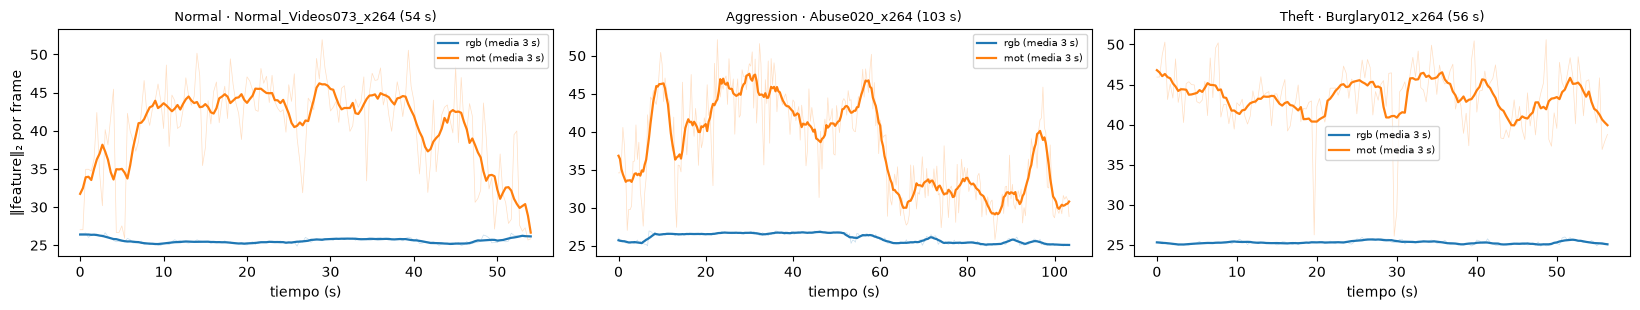

In [15]:
EVERY_N, FPS = 10, 30   # `vad frames`: 1 de cada 10 frames de un video a 30 fps → 1 fila del .npz ≈ 0.33 s
SMOOTH_S = 3            # media móvil (segundos) para ver la tendencia

def float_arrays(z):
    return {k: z[k].astype(np.float32) for k in z.files if z[k].dtype.kind == "f" and z[k].ndim >= 2}

def t_seconds(z, n):
    for k in z.files:                       # si el .npz guarda el nº de frame original, se usa
        a = z[k]
        if a.dtype.kind in "iu" and a.ndim == 1 and len(a) == n:
            return a / FPS
    return np.arange(n) * EVERY_N / FPS

# Un video por clase que SÍ tenga features
demo_feat = []
for c in CLASSES:
    cand = df[(df[LABEL_COL] == c) & df.video_id.map(lambda v: (FEAT_DIR / VARIANT / f"{v}.npz").exists())]
    if len(cand):
        demo_feat.append(cand.sample(1, random_state=SEED).iloc[0])
    else:
        print(f"[AVISO] Ningún video de {c} tiene features en {VARIANT}")

w = max(1, int(round(SMOOTH_S * FPS / EVERY_N)))
fig, axes = plt.subplots(1, max(len(demo_feat), 1), figsize=(5.5 * max(len(demo_feat), 1), 3.2), squeeze=False)
for ax, r in zip(axes[0], demo_feat):
    z = np.load(FEAT_DIR / VARIANT / f"{r.video_id}.npz", allow_pickle=True)
    for k, a in float_arrays(z).items():
        norm = np.linalg.norm(a.reshape(a.shape[0], -1), axis=1)
        t = t_seconds(z, len(norm))
        line, = ax.plot(t, norm, lw=.5, alpha=.25)
        ax.plot(t, pd.Series(norm).rolling(w, center=True, min_periods=1).mean(), lw=1.6,
                color=line.get_color(), label=f"{k} (media {SMOOTH_S} s)")
    ax.set_title(f"{r[LABEL_COL]} · {r.video_id} ({t[-1]:.0f} s)", fontsize=9)
    ax.set_xlabel("tiempo (s)"); ax.legend(fontsize=7)
axes[0, 0].set_ylabel("‖feature‖₂ por frame")
plt.tight_layout(); plt.show()


**Separabilidad de clases:** embedding por video = promedio temporal de cada stream, concatenado; proyección PCA a 2D.

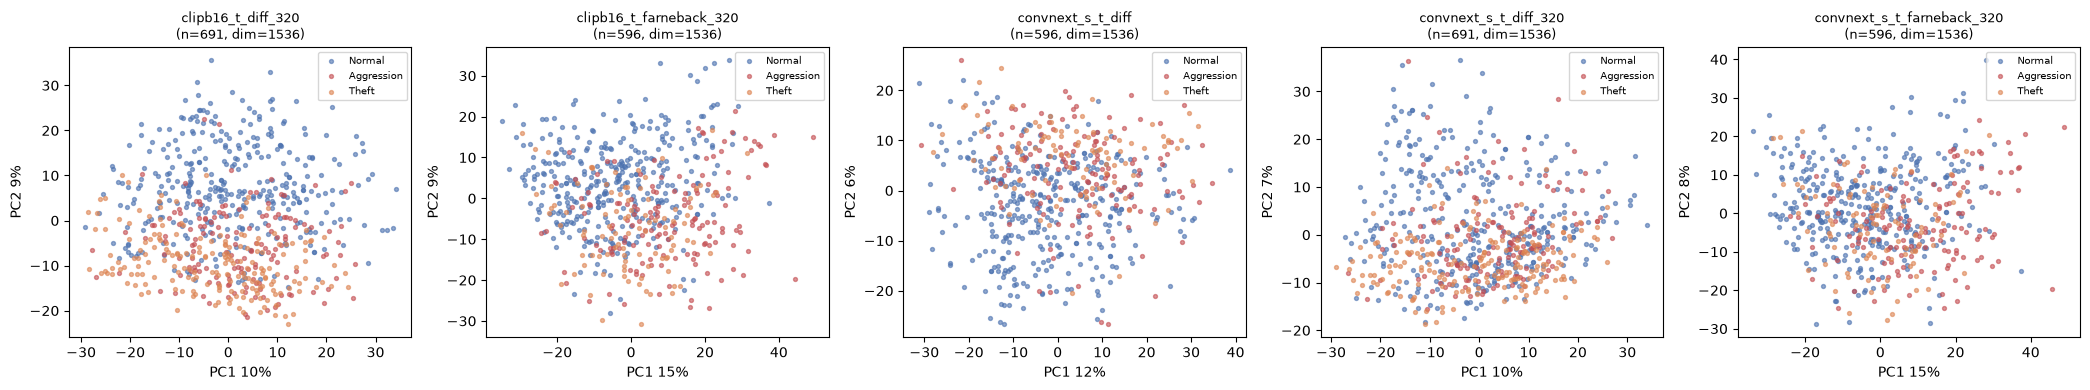

In [16]:
def video_embedding(path):
    parts = [a.reshape(a.shape[0], -1).mean(0) for a in float_arrays(np.load(path, allow_pickle=True)).values()]
    return np.concatenate(parts) if parts else None

def scatter_clases(ax, P, y):
    for c in CLASSES:
        ax.scatter(P[y == c, 0], P[y == c, 1], s=8, alpha=.6, label=c, color=COLORS[c])

def pca_plot(variant, ax):
    X, y = [], []
    for f in sorted((FEAT_DIR / variant).glob("*.npz")):
        if f.stem in label_of:                      # solo videos de las 3 clases
            e = video_embedding(f)
            if e is not None:
                X.append(e); y.append(label_of[f.stem])
    if len(X) < 3:
        ax.set_title(f"{variant}: sin datos"); return
    X = np.stack(X); Xc = (X - X.mean(0)) / (X.std(0) + 1e-6)
    _, S, Vt = np.linalg.svd(Xc, full_matrices=False)
    P = Xc @ Vt[:2].T; var = S**2 / (S**2).sum()
    scatter_clases(ax, P, np.array(y))
    ax.set_title(f"{variant}\n(n={len(X)}, dim={X.shape[1]})", fontsize=9)
    ax.set_xlabel(f"PC1 {var[0]:.0%}"); ax.set_ylabel(f"PC2 {var[1]:.0%}"); ax.legend(fontsize=7)

variants = [p.name for p in sorted(FEAT_DIR.iterdir()) if p.is_dir()]
fig, axes = plt.subplots(1, len(variants), figsize=(4.2 * len(variants), 4), squeeze=False)
for ax, v in zip(axes[0], variants):
    pca_plot(v, ax)
plt.tight_layout(); plt.show()


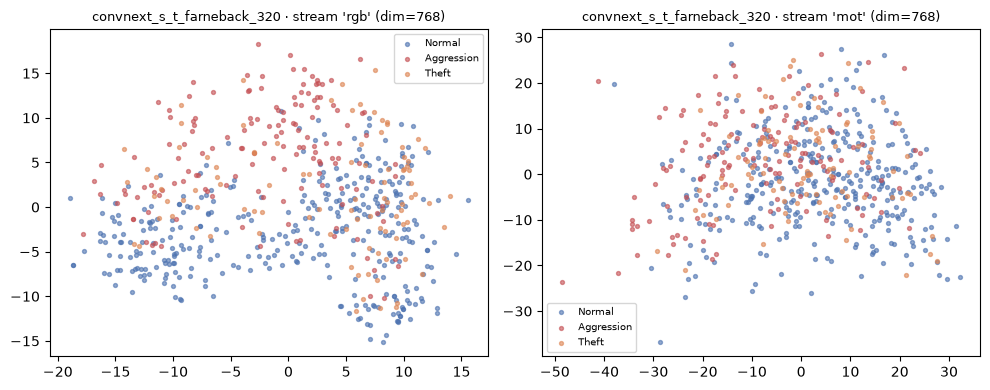

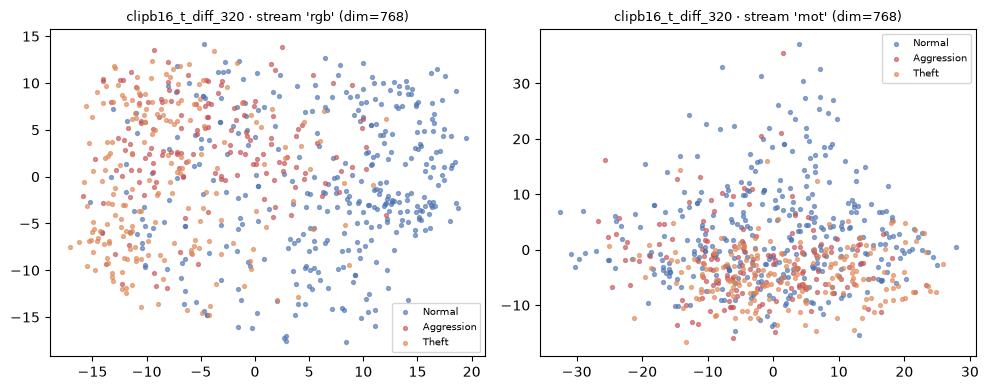

In [17]:
def pca_por_stream(variant):
    if not (FEAT_DIR / variant).exists():
        print("No existe la variante", variant); return
    emb = defaultdict(list); y = []
    for f in sorted((FEAT_DIR / variant).glob("*.npz")):
        if f.stem not in label_of:
            continue
        for k, a in float_arrays(np.load(f, allow_pickle=True)).items():
            emb[k].append(a.reshape(a.shape[0], -1).mean(0))
        y.append(label_of[f.stem])
    y = np.array(y)
    fig, axes = plt.subplots(1, len(emb), figsize=(5 * len(emb), 4), squeeze=False)
    for ax, (k, X) in zip(axes[0], emb.items()):
        X = np.stack(X); Xc = (X - X.mean(0)) / (X.std(0) + 1e-6)
        _, S, Vt = np.linalg.svd(Xc, full_matrices=False); P = Xc @ Vt[:2].T
        scatter_clases(ax, P, y)
        ax.set_title(f"{variant} · stream '{k}' (dim={X.shape[1]})", fontsize=9); ax.legend(fontsize=7)
    plt.tight_layout(); plt.show()

pca_por_stream("convnext_s_t_farneback_320")
pca_por_stream("clipb16_t_diff_320")


## 9. Resumen

In [18]:
resumen = {
    "Clases": {c: CLASS_MAPPING[c] for c in CLASSES},
    "Videos en splits": len(splits),
    "Por split": splits.split.value_counts().to_dict(),
    "Por clase": splits[LABEL_COL].value_counts().reindex(CLASSES).to_dict(),
    "Videos excluidos (calidad)": len(exc),
    "Fuga entre splits": sum(len(sets[a] & sets[b]) for i, a in enumerate(names) for b in names[i + 1:]),
    "Muestreo": f"{L_SEGMENTS} segmentos × 1 frame, {IMG_SIZE}×{IMG_SIZE}",
    "Variantes de features": variants,
}
for k, v in resumen.items():
    print(f"{k:28s}: {v}")


Clases                      : {'Normal': ['NormalVideos'], 'Aggression': ['Assault', 'Abuse', 'Fighting'], 'Theft': ['Robbery', 'Burglary', 'Stealing', 'Shoplifting']}
Videos en splits            : 691
Por split                   : {'train': 390, 'test': 203, 'val': 98}
Por clase                   : {'Normal': 350, 'Aggression': 148, 'Theft': 193}
Videos excluidos (calidad)  : 11
Fuga entre splits           : 0
Muestreo                    : 16 segmentos × 1 frame, 224×224
Variantes de features       : ['clipb16_t_diff_320', 'clipb16_t_farneback_320', 'convnext_s_t_diff', 'convnext_s_t_diff_320', 'convnext_s_t_farneback_320']
